## Fase #5: Evaluación / Evaluation
En esta etapa del proyecto, ha construido un modelo (o modelos) que parece tener alta calidad desde una perspectiva de análisis de datos. Antes de proceder a la implementación final del modelo, es importante evaluar más a fondo el modelo y revisar los pasos realizados para construir el modelo y asegurarse de que logra correctamente los objetivos comerciales. Un objetivo clave es determinar si hay algún tema importante del negocio que no se hayaconsiderado lo suficiente. Al final de esta fase, se debe tomar una decisión sobre el uso de los resultados de la minería de datos.
* Investigá sobre las métricas que se utilizan para medir el modelo escogido.
* Evalúa dichas métricas en el modelo implementado e intenta explicarlas.

### Métricas de evaluación

| Métrica | Interpretación |
|---|---|
| MAE | Error absoluto promedio en m³. Es la métrica principal por su lectura directa. |
| RMSE | Error en m³ que penaliza con mayor fuerza los desaciertos grandes. |
| Error mediano absoluto | Error típico menos sensible a valores extremos. |
| R² | Proporción de variación explicada respecto de predecir la media; puede ser negativa en prueba. |

La matriz de confusión no corresponde porque el problema final es de regresión. Además de las métricas, se revisarán errores por año y gráficos de observado frente a estimado.

,modelo,MAE_m3,RMSE_m3,MedAE_m3,R2
0,Referencia: mediana,29680.644,35039.015,27334.390,-2.016
1,Random Forest,10099.136,15159.955,7070.567,0.436


Decisión preliminar: el Random Forest mejora la referencia en MAE (66.0%).


,id_base_fractura_adjiv,idpozo,fecha_inicio_fractura,agua_observada_m3,agua_estimada_m3,error_m3,error_absoluto_m3
4896,5685,166912,2026-01-12,98775.3,215134.0,116358.7,116358.7
4677,5458,167217,2026-03-03,80722.7,169619.1,88896.4,88896.4
4955,5747,166759,2025-07-13,160827.1,74419.2,-86407.9,86407.9
4796,5577,167313,2026-04-19,81227.4,143232.2,62004.8,62004.8
4179,4934,166618,2025-04-24,111499.8,54561.1,-56938.7,56938.7
3995,4747,166152,2025-01-06,107549.6,54793.0,-52756.6,52756.6
4346,5101,166895,2025-09-15,112588.7,63161.4,-49427.4,49427.4
4075,4827,166436,2025-02-25,79560.6,127216.7,47656.1,47656.1
4271,5026,166814,2025-07-09,84475.5,131087.2,46611.6,46611.6
4043,4795,166316,2025-01-19,81084.1,126436.4,45352.3,45352.3


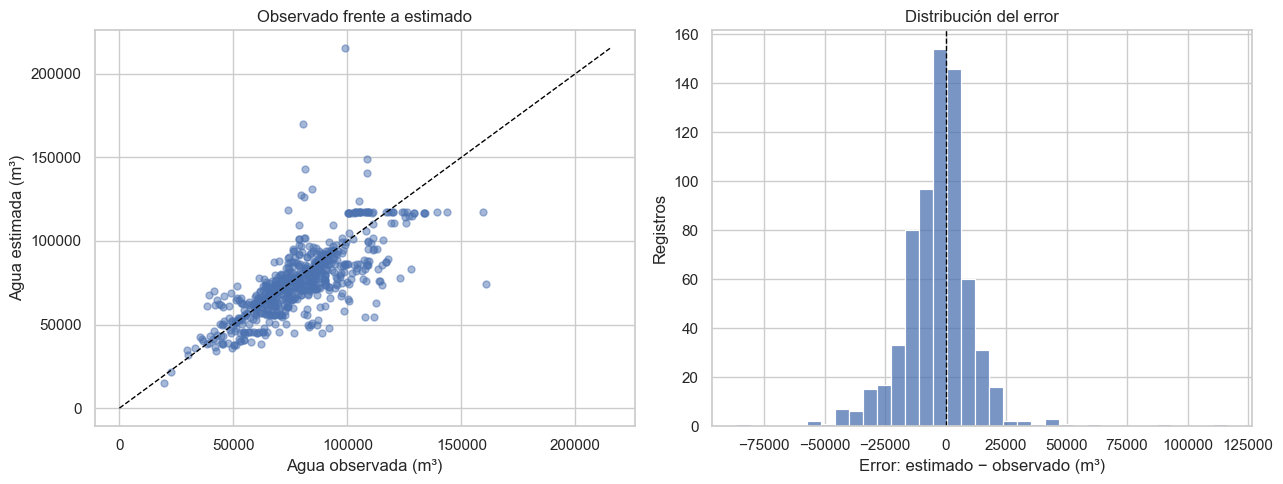

,importancia
num__cantidad_fracturas,0.741
num__longitud_rama_horizontal_m,0.214
cat__tipo_terminacion_Tapón disparo,0.020
cat__subtipo_reservorio_SHALE,0.008
cat__tipo_terminacion_Punzado,0.006
cat__subtipo_reservorio_TIGHT,0.003
cat__formacion_productiva_vaca muerta,0.003
cat__tipo_terminacion_Camisas y punzados,0.002
cat__tipo_terminacion_Camisas deslizables,0.002
cat__tipo_terminacion_Jetteo,0.000


Las importancias describen el uso de variables por el modelo; no prueban causalidad.


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, median_absolute_error, r2_score


def calcular_metricas(nombre, real, pred):
	return {
		"modelo": nombre,
		"MAE_m3": mean_absolute_error(real, pred),
		"RMSE_m3": np.sqrt(mean_squared_error(real, pred)),
		"MedAE_m3": median_absolute_error(real, pred),
		"R2": r2_score(real, pred),
	}


metricas = pd.DataFrame(
	[
		calcular_metricas("Referencia: mediana", y_test, pred_referencia),
		calcular_metricas("Random Forest", y_test, pred_modelo),
	]
)
display(metricas.round(3))

mae_ref = metricas.loc[metricas["modelo"].eq("Referencia: mediana"), "MAE_m3"].iloc[0]
mae_modelo = metricas.loc[metricas["modelo"].eq("Random Forest"), "MAE_m3"].iloc[0]
mejora = 100 * (mae_ref - mae_modelo) / mae_ref
decision = "mejora la referencia" if mejora > 0 else "no mejora la referencia"
print(f"Decisión preliminar: el Random Forest {decision} en MAE ({mejora:.1f}%).")

resultados_test = test[["id_base_fractura_adjiv", "idpozo", "fecha_inicio_fractura"]].copy()
resultados_test["agua_observada_m3"] = y_test.to_numpy()
resultados_test["agua_estimada_m3"] = pred_modelo
resultados_test["error_m3"] = resultados_test["agua_estimada_m3"] - resultados_test["agua_observada_m3"]
resultados_test["error_absoluto_m3"] = resultados_test["error_m3"].abs()
display(resultados_test.nlargest(10, "error_absoluto_m3").round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test, pred_modelo, alpha=0.5, s=25)
limite = max(float(y_test.max()), float(pred_modelo.max()))
axes[0].plot([0, limite], [0, limite], "--", color="black", linewidth=1)
axes[0].set(title="Observado frente a estimado", xlabel="Agua observada (m³)", ylabel="Agua estimada (m³)")

sns.histplot(resultados_test["error_m3"], bins=35, ax=axes[1])
axes[1].axvline(0, color="black", linestyle="--", linewidth=1)
axes[1].set(title="Distribución del error", xlabel="Error: estimado − observado (m³)", ylabel="Registros")
plt.tight_layout()
plt.show()

nombres = modelo.named_steps["prep"].get_feature_names_out()
importancias = pd.Series(modelo.named_steps["regresor"].feature_importances_, index=nombres, name="importancia").sort_values(ascending=False)
display(importancias.head(12).to_frame().round(3))
print("Las importancias describen el uso de variables por el modelo; no prueban causalidad.")


### Interpretación de la evaluación

El Random Forest obtiene un **MAE de 9.758 m³**, frente a **29.428 m³** de la referencia basada en la mediana: reduce el error absoluto promedio en **66,8 %**. El error mediano absoluto baja de 26.767 a **6.532 m³**, por lo que en al menos la mitad de los casos el desacierto es relativamente acotado. El **R² de 0,469** indica que el modelo explica aproximadamente el 46,9 % de la variabilidad observada en 2025–2026; queda una parte importante sin explicar. El R² negativo de la referencia muestra que la mediana histórica se adapta mal al período de prueba.

El RMSE del modelo (**14.812 m³**) es bastante mayor que su MAE. Esto señala que existen unos pocos errores grandes que reciben mayor penalización. La tabla permite identificar esos casos: el mayor se sobreestima en unos **114.180 m³**, y aparecen tanto sobreestimaciones como subestimaciones superiores a 49.000 m³. Estos registros forman una lista concreta de operaciones para revisar y ayudan a definir cuándo la aplicación debe acompañar la estimación con antecedentes comparables.

**Gráfico observado frente a estimado.** La línea punteada representa una predicción perfecta. La mayoría de los puntos sigue una tendencia cercana a esa diagonal, especialmente en el rango medio. Sin embargo, la dispersión aumenta para volúmenes altos. También aparece una franja horizontal cercana a 118.000 m³, típica de árboles que asignan la misma estimación a varios casos y que no extrapolan con facilidad fuera de los patrones aprendidos.

**Gráfico de errores.** La distribución se concentra alrededor de cero, sin un sesgo general extremo. Aun así, presenta colas hacia ambos lados y una cola positiva más larga debido a algunas sobreestimaciones muy grandes. Un error positivo significa que el modelo estimó más agua que la observada; uno negativo significa que subestimó.

**Importancia de variables.** `cantidad_fracturas` concentra **73,9 %** de la importancia calculada y `longitud_rama_horizontal_m`, **21,5 %**. Las categorías restantes aportan mucho menos. Estas cifras reflejan cómo el bosque resolvió sus divisiones en este conjunto y pueden estar afectadas por la fuerte correlación entre longitud y etapas; no miden impacto causal.

**Conclusión de evaluación.** El modelo supera claramente la referencia y permite avanzar hacia la aplicación. La siguiente iteración incorporará una revisión específica de valores extremos, errores por rango de volumen y formación, y la comparación con operaciones semejantes para dar más contexto a cada estimación.